In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score

import warnings
warnings.filterwarnings('ignore')

print("All libraries imported successfully!")

All libraries imported successfully!


In [7]:
df = pd.read_csv("/Users/kaushikee/E-Commerce-Customer-Segmentation/Dataset/OnlineRetail.csv",encoding="latin1")

print("Dataset loaded successfully!")
print("Shape of dataset:", df.shape)

df.head()

Dataset loaded successfully!
Shape of dataset: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  str    
 1   StockCode    541909 non-null  str    
 2   Description  540455 non-null  str    
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  str    
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 33.1 MB


In [9]:
df.describe()

,Quantity,UnitPrice,CustomerID
count,541909.000000,541909.000000,406829.000000
mean,9.552250,4.611114,15287.690570
std,218.081158,96.759853,1713.600303
min,-80995.000000,-11062.060000,12346.000000
25%,1.000000,1.250000,13953.000000
50%,3.000000,2.080000,15152.000000
75%,10.000000,4.130000,16791.000000
max,80995.000000,38970.000000,18287.000000


In [10]:
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [11]:
df.duplicated().sum()

np.int64(5268)

In [12]:
df["CustomerID"].nunique()

4372

In [13]:
df.columns

Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='str')

In [14]:
df["InvoiceNo"].astype(str).str.startswith("C").sum()

np.int64(9288)

In [15]:
df["CustomerID"].isnull().sum()

np.int64(135080)

In [16]:
(df["Quantity"] <= 0).sum()

np.int64(10624)

In [17]:
(df["UnitPrice"] <= 0).sum()

np.int64(2517)

In [18]:
df = df[~df["InvoiceNo"].astype(str).str.startswith("C")]
df = df.dropna(subset=["CustomerID"])
df = df[df["Quantity"] > 0]
df = df[df["UnitPrice"] > 0]

print("Data cleaned successfully!")
print("Shape after cleaning:", df.shape)

Data cleaned successfully!
Shape after cleaning: (397884, 8)


In [19]:
print("Missing CustomerID:", df["CustomerID"].isnull().sum())
print("Cancelled transactions:", df["InvoiceNo"].astype(str).str.startswith("C").sum())
print("Invalid quantities:", (df["Quantity"] <= 0).sum())
print("Invalid prices:", (df["UnitPrice"] <= 0).sum())

Missing CustomerID: 0
Cancelled transactions: 0
Invalid quantities: 0
Invalid prices: 0


In [20]:
df["TotalAmount"] = df["Quantity"] * df["UnitPrice"]

df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalAmount
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom,20.34


In [21]:
df["TotalAmount"].describe()

count    397884.000000
mean         22.397000
std         309.071041
min           0.001000
25%           4.680000
50%          11.800000
75%          19.800000
max      168469.600000
Name: TotalAmount, dtype: float64

In [22]:
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

print("Date converted successfully!")

Date converted successfully!


In [23]:
analysis_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)

rfm = df.groupby("CustomerID").agg({
    "InvoiceDate": lambda x: (analysis_date - x.max()).days,
    "InvoiceNo": "nunique",
    "TotalAmount": "sum"
})

rfm.columns = ["Recency", "Frequency", "Monetary"]

rfm.head()

,Recency,Frequency,Monetary
CustomerID,,,
12346.0,326,1,77183.60
12347.0,2,7,4310.00
12348.0,75,4,1797.24
12349.0,19,1,1757.55
12350.0,310,1,334.40


In [24]:
print("RFM Dataset Shape:", rfm.shape)
rfm.describe()

RFM Dataset Shape: (4338, 3)


,Recency,Frequency,Monetary
count,4338.000000,4338.000000,4338.000000
mean,92.536422,4.272015,2054.266460
std,100.014169,7.697998,8989.230441
min,1.000000,1.000000,3.750000
25%,18.000000,1.000000,307.415000
50%,51.000000,2.000000,674.485000
75%,142.000000,5.000000,1661.740000
max,374.000000,209.000000,280206.020000


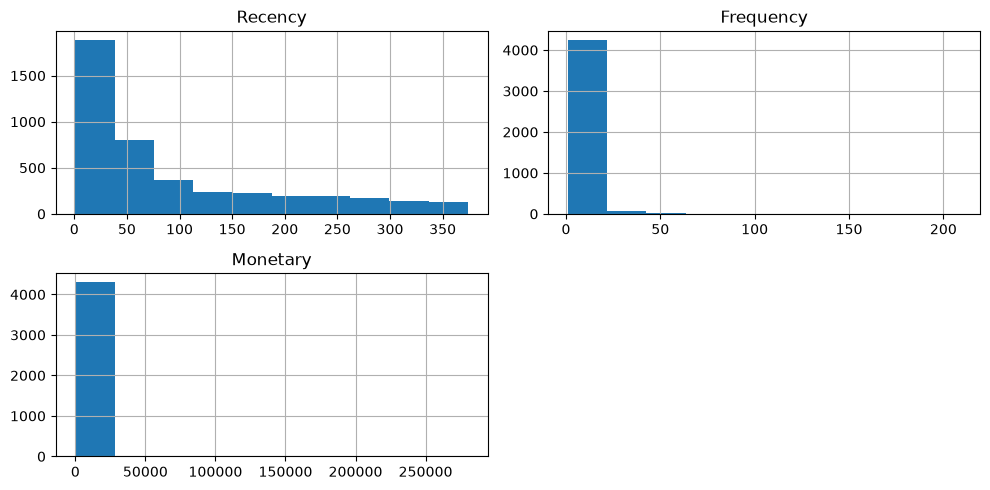

In [25]:
rfm.hist(figsize=(10, 5))
plt.tight_layout()
plt.show()

In [26]:
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm)

print("Scaling completed!")

Scaling completed!


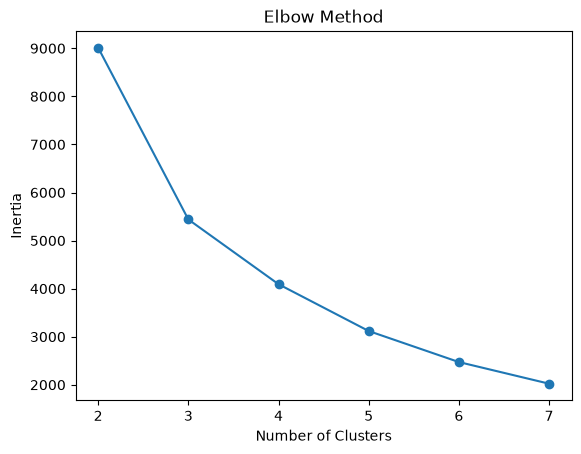

In [27]:
inertia = []

for k in range(2, 8):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(rfm_scaled)
    inertia.append(model.inertia_)

plt.plot(range(2, 8), inertia, marker='o')
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()

In [28]:
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)

rfm["KMeans_Cluster"] = kmeans.fit_predict(rfm_scaled)

print(rfm["KMeans_Cluster"].value_counts())

KMeans_Cluster
0    3054
1    1067
3     204
2      13
Name: count, dtype: int64


In [29]:
dbscan = DBSCAN(eps=0.5, min_samples=5)

rfm["DBSCAN_Cluster"] = dbscan.fit_predict(rfm_scaled)

print(rfm["DBSCAN_Cluster"].value_counts())

DBSCAN_Cluster
 0    4284
-1      54
Name: count, dtype: int64


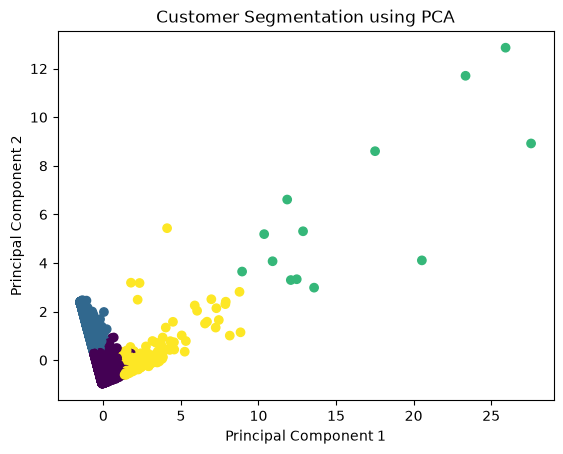

In [30]:
pca = PCA(n_components=2)
pca_result = pca.fit_transform(rfm_scaled)

plt.scatter(
    pca_result[:, 0],
    pca_result[:, 1],
    c=rfm["KMeans_Cluster"],
    cmap="viridis"
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Customer Segmentation using PCA")
plt.show()

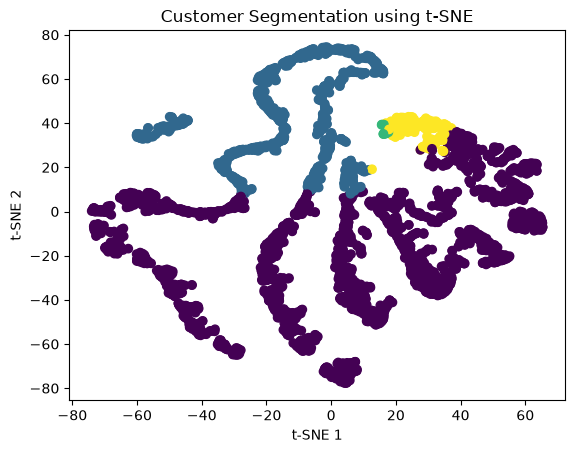

In [31]:
tsne = TSNE(n_components=2, random_state=42, perplexity=30)

tsne_result = tsne.fit_transform(rfm_scaled)

plt.scatter(
    tsne_result[:, 0],
    tsne_result[:, 1],
    c=rfm["KMeans_Cluster"],
    cmap="viridis"
)

plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.title("Customer Segmentation using t-SNE")
plt.show()

In [32]:
cluster_summary = rfm.groupby("KMeans_Cluster")[
    ["Recency", "Frequency", "Monetary"]
].mean().round(2)

cluster_summary

,Recency,Frequency,Monetary
KMeans_Cluster,,,
0,43.70,3.68,1359.05
1,248.08,1.55,480.62
2,7.38,82.54,127338.31
3,15.50,22.33,12709.09


In [33]:
print(cluster_summary)

                Recency  Frequency   Monetary
KMeans_Cluster                               
0                 43.70       3.68    1359.05
1                248.08       1.55     480.62
2                  7.38      82.54  127338.31
3                 15.50      22.33   12709.09
